# Choropleth Plotting Examples

Two examples of the [`laser.core.plotting.choropleth`](../src/laser/core/plotting.py)
helper for rendering spatial maps of per-region quantities:

1. **Single choropleth** — plot the initial population of Mali's admin-2 regions from
   the `MLI_admin2.gpkg` GeoPackage bundled next to this notebook.
2. **3-column × 2-row grid** — six panels of stochastic per-patch values, showing how
   to compose `choropleth()` with a Matplotlib subplot grid via the `ax=` parameter.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from laser.core.plotting import choropleth


## (a) Single choropleth — Mali admin-2 population

`MLI_admin2.gpkg` (bundled next to this notebook) contains 160 admin-2 regions of
Mali with a `population` column. Populations span several orders of magnitude across
regions, so we plot on a log scale (`log=True` renders `log10(1 + value)`).


loaded 160 regions; columns = ['adm2_name', 'dot_name', 'adm2_pcode', 'name', 'nodeid', 'population', 'geometry']
population: min=832  max=2,282,896  median=58,502


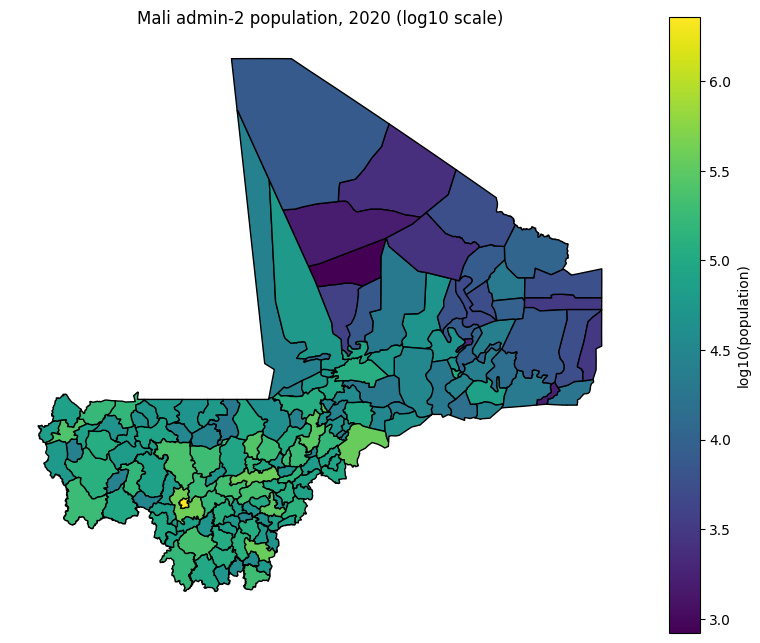

In [2]:
gpkg = Path.cwd() / "MLI_admin2.gpkg"
gdf = gpd.read_file(gpkg)
print(f"loaded {len(gdf)} regions; columns = {list(gdf.columns)}")
print(f"population: min={gdf['population'].min():,}  max={gdf['population'].max():,}  median={int(gdf['population'].median()):,}")

choropleth(
    gdf,
    column="population",
    log=True,
    title="Mali admin-2 population, 2020 (log10 scale)",
    legend_label="log10(population)",
    cmap="viridis",
    figsize=(10, 8),
);


## (b) 3×2 grid — stochastic per-patch values

Six independent random draws over the same 160 Mali regions, laid out in a
3-column × 2-row grid. Think of each panel as a different stochastic realization,
scenario, or snapshot in time. The key API pattern is passing an existing Matplotlib
`Axes` into each `choropleth()` call via `ax=` — the helper then draws into that
subplot instead of creating its own figure.

We use `values=...` (rather than `column=...`) to hand `choropleth()` an
array of per-region values that isn't already stored on the GeoPackage; the array
must have one entry per row of `gdf`, in row order.

> **Note on shared scales.** `choropleth()` currently auto-scales its colorbar per
> panel, so raw colors are not directly comparable across panels. Match on rank or
> spatial pattern rather than absolute color. If you need a shared range, pre-normalize
> your values into a common scale, or extend the helper to expose `vmin` / `vmax`.


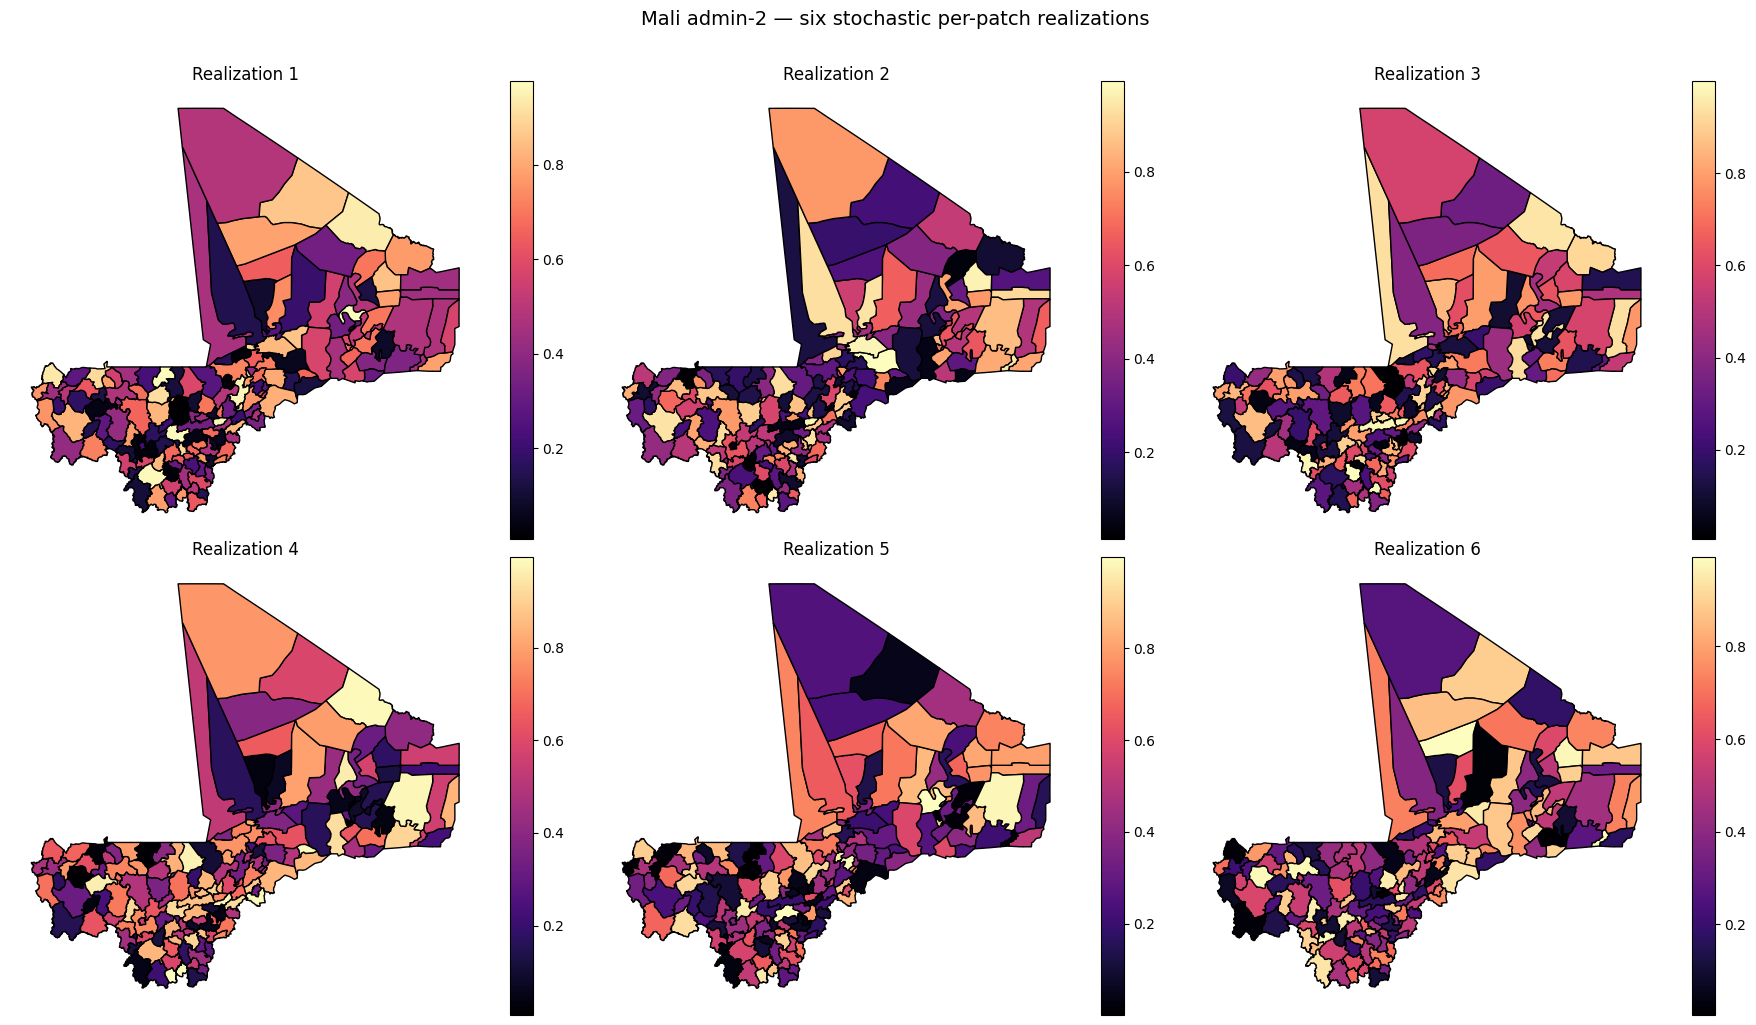

In [3]:
n_patches = len(gdf)
rng = np.random.default_rng(42)

# Six independent per-patch draws — e.g. six stochastic realizations of an attack-rate
# metric, or the same metric evaluated at six different simulation snapshots.
scenarios = [
    ("Realization 1", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 2", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 3", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 4", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 5", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 6", rng.uniform(0.0, 1.0, n_patches)),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, values) in zip(axes.flat, scenarios):
    choropleth(
        gdf,
        values=values,
        column="attack_rate",  # attach values under this name (used for the panel title default too)
        title=name,
        legend=True,
        cmap="magma",
        ax=ax,
    )

fig.suptitle("Mali admin-2 — six stochastic per-patch realizations", fontsize=14, y=1.02)
plt.tight_layout()


### Recap

- **Example (a)** uses `column=` to plot an existing GeoPackage column, and `log=True`
  to compress the wide dynamic range of raw population counts.
- **Example (b)** uses `values=` to attach arbitrary per-region data at plot time, and
  `ax=` to compose several panels into a shared figure. Any Matplotlib subplot layout
  works — `plt.subplots(rows, cols)` is the simplest.
